# Roomors: Hotel Booking Analytics and Cancellation Risk Prioritization
Group 4.2 - Job Russel Enriquez and John Cyruz Patron

Parts B-C: descriptive recap and chronological predictive evaluation. Run all cells in order. The included outputs are from the supplied source CSV. See the README and paper for limitations.

In [ ]:
%pip install pandas==2.3.3 numpy==2.0.2 scikit-learn==1.6.1 matplotlib==3.9.4

In [ ]:
from pathlib import Path
import shutil
Path('data').mkdir(exist_ok=True)
if not Path('data/hotel_bookings.csv').exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_name = next(name for name in uploaded if name.endswith('.csv'))
        shutil.copyfile(csv_name, 'data/hotel_bookings.csv')
    except ImportError:
        raise FileNotFoundError('Place hotel_bookings.csv in the data folder beside this notebook.')

## Method
Exact deduplication matches Part A. A 60/20/20 creation-date partition is purged of unresolved training/validation labels. Preprocessing fits only training observations. Average precision on validation selects a model. Final-test results do not alter selection. Threshold is fixed at 0.50. Candidate input values require prospective availability auditing.

In [1]:
"""Reproduce descriptive analysis and booking-time cancellation prediction."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix, brier_score_loss
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay,PrecisionRecallDisplay
ROOT=Path.cwd()
OUT=ROOT/'results';OUT.mkdir(exist_ok=True)
raw=pd.read_csv(ROOT/'data/hotel_bookings.csv')
df=raw.drop_duplicates().copy()
df['arrival_date']=pd.to_datetime(dict(year=df.arrival_date_year,month=pd.to_datetime(df.arrival_date_month,format='%B').dt.month,day=df.arrival_date_day_of_month))
df['booking_date']=df.arrival_date-pd.to_timedelta(df.lead_time,unit='D')
df['total_nights']=df.stays_in_weekend_nights+df.stays_in_week_nights
df['arrival_month_number']=df.arrival_date.dt.month
# Raw inputs remain unimputed: preprocessing is learned on training rows only.
num=['lead_time','arrival_month_number','arrival_date_day_of_month','stays_in_weekend_nights','stays_in_week_nights','adults','children','babies']
cat=['hotel','meal','market_segment','distribution_channel','reserved_room_type','customer_type','country']
features=num+cat
# Booking creation time is inferred; labels must have resolved before each scoring date.
# All same-date bookings stay together. Validation selects the model before final test.
dates=df.booking_date.sort_values().reset_index(drop=True)
cut1=dates.iloc[int(len(dates)*.60)];cut2=dates.iloc[int(len(dates)*.80)]
resolved=pd.to_datetime(df.reservation_status_date)
train=df[(df.booking_date<cut1)&(resolved<cut1)].copy()
valid=df[(df.booking_date>=cut1)&(df.booking_date<cut2)].copy()
# Validation labels available by test origin; exclude still-unresolved validation records.
valid=valid[pd.to_datetime(valid.reservation_status_date)<cut2].copy()
test=df[df.booking_date>=cut2].copy()
assert train.booking_date.max()<valid.booking_date.min()<=valid.booking_date.max()<test.booking_date.min()
assert pd.to_datetime(train.reservation_status_date).max()<cut1
assert pd.to_datetime(valid.reservation_status_date).max()<cut2

def pipeline(model):
 pre=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('category',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),cat)])
 return Pipeline([('prepare',pre),('model',model)])
def metrics(y,p):
 pred=p>=.5
 return dict(accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,zero_division=0),recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),roc_auc=roc_auc_score(y,p),average_precision=average_precision_score(y,p),brier=brier_score_loss(y,p),tn=int(confusion_matrix(y,pred)[0,0]),fp=int(confusion_matrix(y,pred)[0,1]),fn=int(confusion_matrix(y,pred)[1,0]),tp=int(confusion_matrix(y,pred)[1,1]))
models={'Majority baseline':DummyClassifier(strategy='most_frequent'),'Logistic regression':LogisticRegression(max_iter=1200,C=1,random_state=42),'Random forest':RandomForestClassifier(n_estimators=160,max_depth=14,min_samples_leaf=15,max_features='sqrt',n_jobs=-1,random_state=42)}
rows=[];fitted={}
for name,m in models.items():
 print('Training',name,flush=True)
 pipe=pipeline(m);pipe.fit(train[features],train.is_canceled);fitted[name]=pipe
 for label,part in [('train',train),('validation',valid)]:
  rows.append(dict(model=name,split=label,n=len(part),**metrics(part.is_canceled,pipe.predict_proba(part[features])[:,1])))
validation=pd.DataFrame(rows)
winner=validation[(validation.split=='validation')&(validation.model!='Majority baseline')].sort_values('average_precision',ascending=False).iloc[0].model
# No final-test model selection or threshold tuning. Compare predeclared models once.
for name,pipe in fitted.items():
 rows.append(dict(model=name,split='test',n=len(test),**metrics(test.is_canceled,pipe.predict_proba(test[features])[:,1])))
metrics_df=pd.DataFrame(rows);metrics_df.to_csv(OUT/'model_metrics.csv',index=False)
p=fitted[winner].predict_proba(test[features])[:,1]
test_out=test.copy();test_out['predicted_cancellation_risk']=p
test_out.to_csv(OUT/'heldout_predictions.csv',index=False)
# Operational ranking: a prespecified capacity of 10% of heldout bookings.
k=max(1,int(np.ceil(len(test)*.1)));top=test_out.sort_values('predicted_cancellation_risk',ascending=False).head(k)
rank=dict(flagged=k,canceled=int(top.is_canceled.sum()),precision=float(top.is_canceled.mean()),capture=float(top.is_canceled.sum()/test.is_canceled.sum()),base_rate=float(test.is_canceled.mean()),lift=float(top.is_canceled.mean()/test.is_canceled.mean()))
# Permutation importance uses validation data, never the final-test labels.
from sklearn.inspection import permutation_importance
sample=valid.sample(min(3500,len(valid)),random_state=42)
imp=permutation_importance(fitted[winner],sample[features],sample.is_canceled,scoring='average_precision',n_repeats=3,random_state=42,n_jobs=1)
pd.DataFrame({'feature':features,'importance_mean':imp.importances_mean,'importance_sd':imp.importances_std}).sort_values('importance_mean',ascending=False).to_csv(OUT/'feature_importance.csv',index=False)
# Sensitivity check: evaluate the selected model on raw records, with the same date boundaries.
rr=raw.copy();rr['arrival_month_number']=pd.to_datetime(rr.arrival_date_month,format='%B').dt.month
rr['arrival_date']=pd.to_datetime(dict(year=rr.arrival_date_year,month=rr.arrival_month_number,day=rr.arrival_date_day_of_month));rr['booking_date']=rr.arrival_date-pd.to_timedelta(rr.lead_time,unit='D')
rtrain=rr[(rr.booking_date<cut1)&(pd.to_datetime(rr.reservation_status_date)<cut1)]
rtest=rr[rr.booking_date>=cut2]
from sklearn.base import clone
raw_model=clone(fitted[winner]);raw_model.fit(rtrain[features],rtrain.is_canceled)
sensitivity=metrics(rtest.is_canceled,raw_model.predict_proba(rtest[features])[:,1])
# Descriptive exports preserve Part A's deduplicated analytical basis.
df.to_csv(ROOT/'data/hotel_bookings_analysis.csv',index=False)
for column in ['hotel','market_segment']:
 g=df.groupby(column).is_canceled.agg(bookings='size',cancellations='sum',cancellation_rate='mean').reset_index();g.to_csv(OUT/f'{column}_summary.csv',index=False)
lead=pd.cut(df.lead_time,[-1,7,30,90,180,365,np.inf],labels=['0-7','8-30','31-90','91-180','181-365','366+'])
df.groupby(lead,observed=False).is_canceled.agg(bookings='size',cancellation_rate='mean').to_csv(OUT/'lead_time_summary.csv')
summary=dict(raw_rows=len(raw),analysis_rows=len(df),duplicates_removed=len(raw)-len(df),cancellations=int(df.is_canceled.sum()),cancellation_rate=float(df.is_canceled.mean()),raw_cancellation_rate=float(raw.is_canceled.mean()),cutoff_validation=str(cut1.date()),cutoff_test=str(cut2.date()),selected_model=winner,ranking=rank,raw_sensitivity=sensitivity,features=features,excluded_train_unresolved=int(((df.booking_date<cut1)&(resolved>=cut1)).sum()),excluded_validation_unresolved=int(((df.booking_date>=cut1)&(df.booking_date<cut2)&(resolved>=cut2)).sum()),splits={label:dict(n=len(part),start=str(part.booking_date.min().date()),end=str(part.booking_date.max().date()),cancellation_rate=float(part.is_canceled.mean())) for label,part in [('train',train),('validation',valid),('test',test)]})
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(7,4));g=pd.read_csv(OUT/'hotel_summary.csv');ax.bar(g.hotel,g.cancellation_rate*100,color=['#315b75','#bc674e']);ax.set(ylabel='Cancellation rate (%)',title='Cancellation rate by hotel (deduplicated data)');fig.tight_layout();fig.savefig(OUT/'hotel_rates.png',dpi=200);plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for name,pipe in fitted.items():
 pp=pipe.predict_proba(test[features])[:,1]
 RocCurveDisplay.from_predictions(test.is_canceled,pp,name=name,ax=axes[0]);PrecisionRecallDisplay.from_predictions(test.is_canceled,pp,name=name,ax=axes[1])
fig.tight_layout();fig.savefig(OUT/'model_curves.png',dpi=200);plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4));im=pd.read_csv(OUT/'feature_importance.csv').head(8).iloc[::-1];ax.barh(im.feature,im.importance_mean,color='#315b75');ax.set(xlabel='Decrease in validation average precision',title='Permutation importance (3 repeats)');fig.tight_layout();fig.savefig(OUT/'importance.png',dpi=200);plt.close(fig)
fig,axes=plt.subplots(2,1,figsize=(7,6))
ld=pd.read_csv(OUT/'lead_time_summary.csv');axes[0].bar(ld.iloc[:,0],ld.cancellation_rate*100,color='#bc674e');axes[0].set(ylabel='Cancellation rate (%)',xlabel='Lead time (days)')
monthly=df.groupby(df.arrival_date.dt.to_period('M')).size();axes[1].plot(monthly.index.to_timestamp(),monthly.values,color='#315b75');axes[1].set(ylabel='Recorded bookings',xlabel='Arrival month');fig.autofmt_xdate();fig.tight_layout();fig.savefig(OUT/'eda_patterns.png',dpi=200);plt.close(fig)
print(json.dumps(summary,indent=2));print(metrics_df.to_string(index=False))


Training Majority baseline
Training Logistic regression
Training Random forest
{
  "raw_rows": 119390,
  "analysis_rows": 87396,
  "duplicates_removed": 31994,
  "cancellations": 24025,
  "cancellation_rate": 0.27489816467572886,
  "raw_cancellation_rate": 0.37041628277075134,
  "cutoff_validation": "2016-09-21",
  "cutoff_test": "2017-01-28",
  "selected_model": "Logistic regression",
  "ranking": {
    "flagged": 1757,
    "canceled": 977,
    "precision": 0.556061468412066,
    "capture": 0.20082219938335047,
    "base_rate": 0.2770343374523091,
    "lift": 2.0071933086915297
  },
  "raw_sensitivity": {
    "accuracy": 0.7309512902733242,
    "precision": 0.6134655846107604,
    "recall": 0.3378579705346797,
    "f1": 0.4357386848847139,
    "roc_auc": 0.7354852515357415,
    "average_precision": 0.5662745912858047,
    "brier": 0.18294694283328816,
    "tn": 12320,
    "fp": 1286,
    "fn": 4000,
    "tp": 2041
  },
  "features": [
    "lead_time",
    "arrival_month_number",
    "

model,split,n,accuracy,precision,recall,f1,roc_auc,average_precision,brier,tn,fp,fn,tp
Majority baseline,train,45428,0.723563,0.000000,0.000000,0.000000,0.500000,0.276437,0.276437,32870,0,12558,0
Majority baseline,validation,9924,0.632104,0.000000,0.000000,0.000000,0.500000,0.367896,0.367896,6273,0,3651,0
Logistic regression,train,45428,0.769349,0.637059,0.384934,0.479897,0.794786,0.602417,0.155168,30116,2754,7724,4834
Logistic regression,validation,9924,0.711004,0.758075,0.314982,0.445046,0.791014,0.703071,0.187033,5906,367,2501,1150
Random forest,train,45428,0.760984,0.823686,0.172241,0.284905,0.838084,0.668422,0.153127,32407,463,10395,2163
Random forest,validation,9924,0.656086,0.869565,0.076691,0.140951,0.825314,0.698610,0.189060,6231,42,3371,280
Majority baseline,test,17561,0.722966,0.000000,0.000000,0.000000,0.500000,0.277034,0.277034,12696,0,4865,0
Logistic regression,test,17561,0.731849,0.540248,0.215211,0.307805,0.718044,0.469361,0.179778,11805,891,3818,1047
Random forest,test,17561,0.727407,0.630872,0.038643,0.072826,0.750054,0.496272,0.172805,12586,110,4677,188


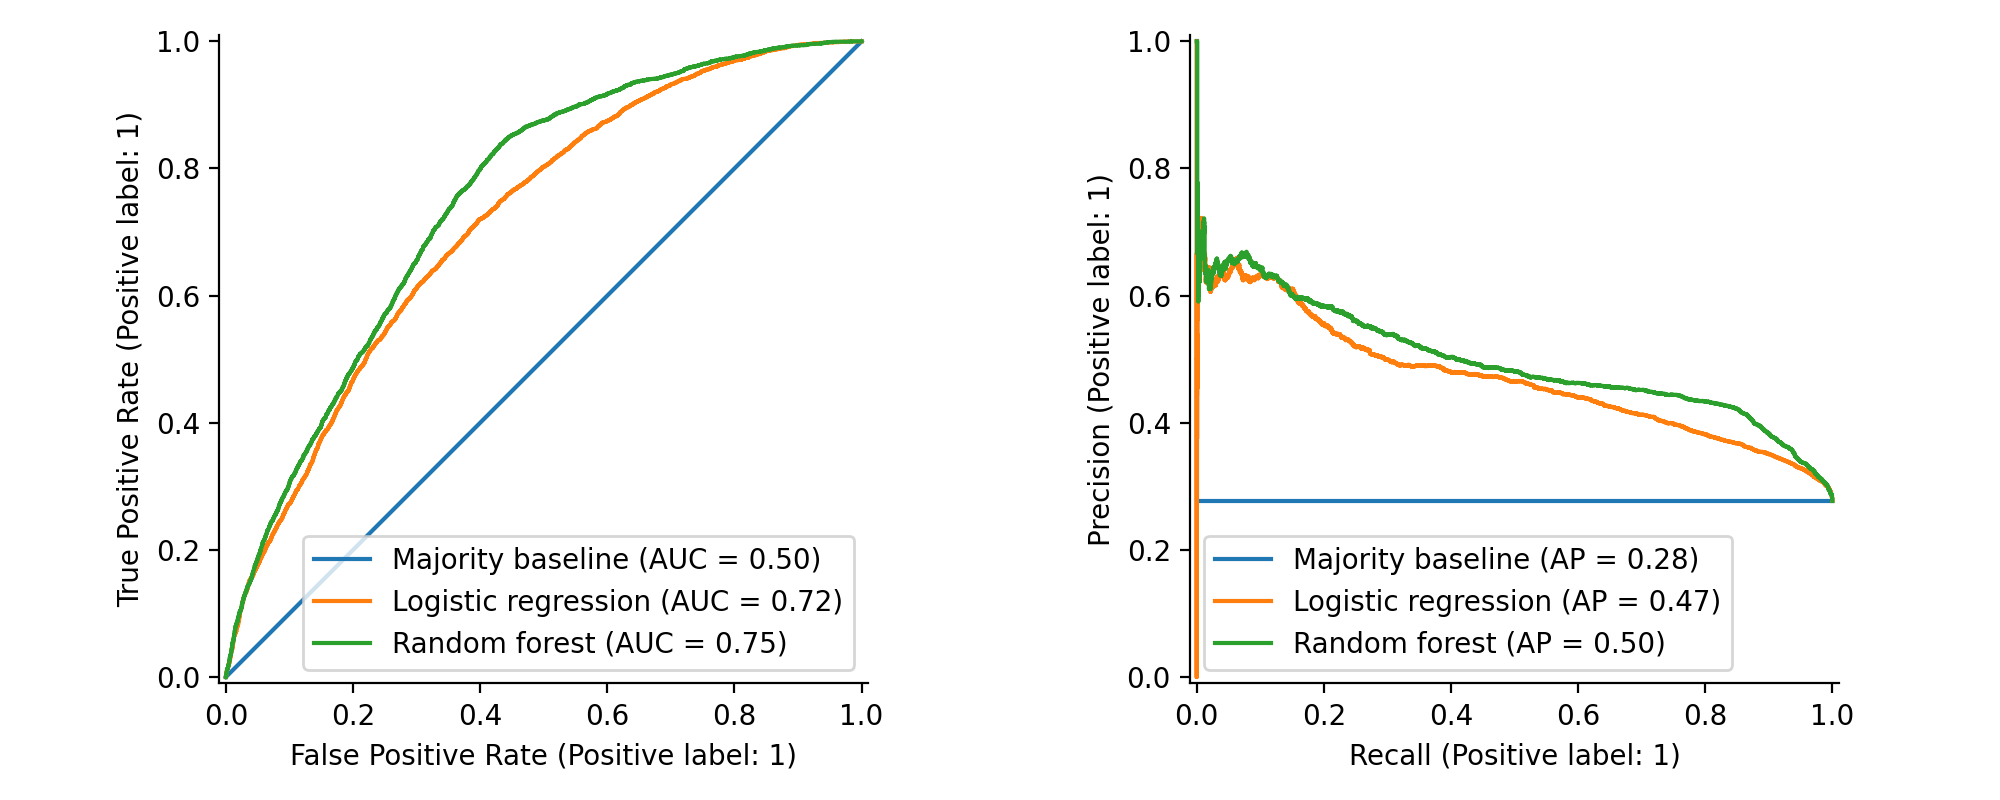

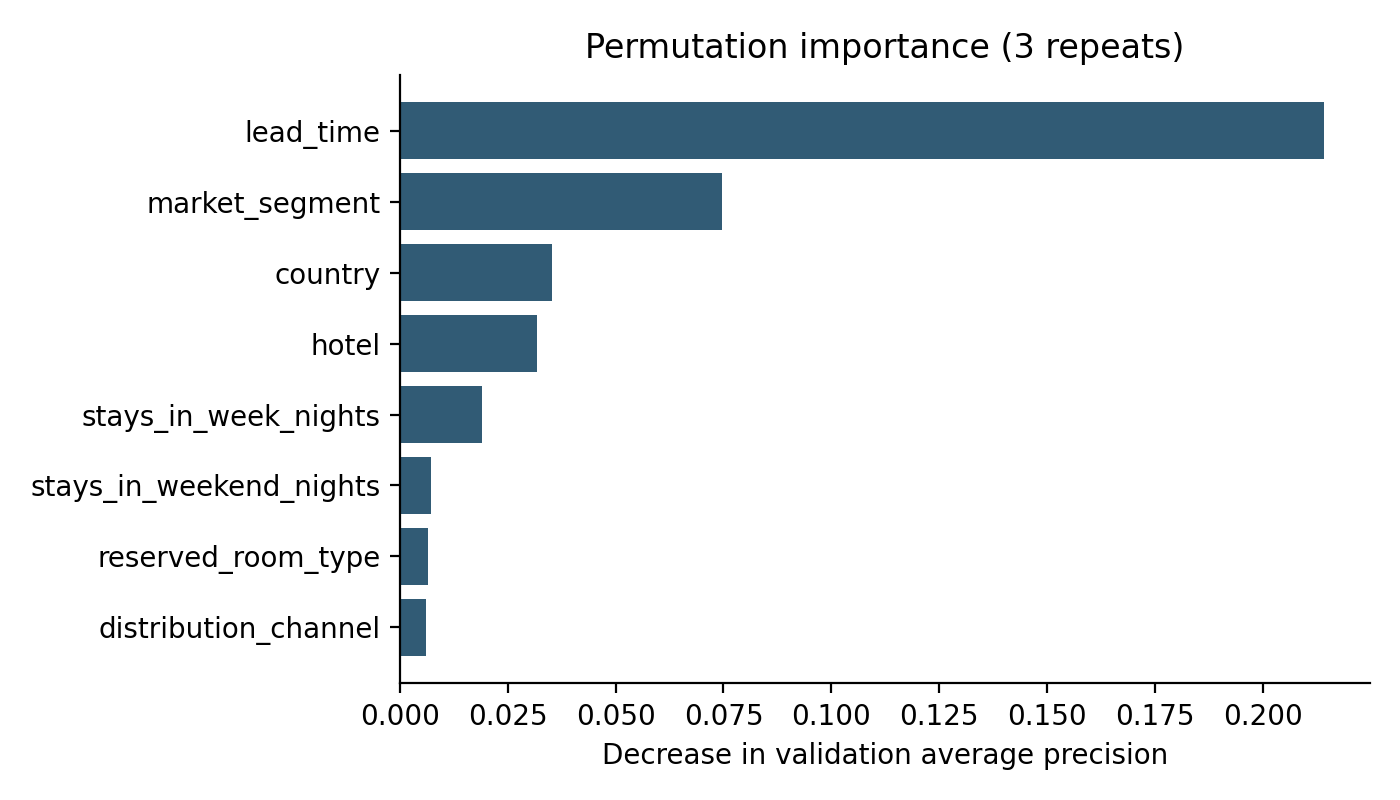

In [2]:
from IPython.display import display, Image
display(pd.read_csv('results/model_metrics.csv'))
display(Image(filename='results/model_curves.png'))
display(Image(filename='results/importance.png'))

## Interpretation
Logistic regression was selected on validation AP (0.7031). Test ROC-AUC is 0.7180 and AP is 0.4694, with recall only 0.2152 at threshold 0.50. The top-decile queue is enriched for cancellations (55.61% vs 27.70%) but captures only 20.08% of all test cancellations. A randomized follow-up pilot is needed before claiming cancellation reduction. Random forest generalizes differently and has higher test ranking metrics, but switching models using this test would invalidate the original selection procedure. Historical snapshot values, arrival-window truncation, duplicate assumptions, and drift constrain operational use.